# ASSIGNMENT 6 - NumPy, SciPy, File I/O and Visualization

In [1]:
# Imports
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats, linalg, optimize, integrate

## Question 1: Temperature Analysis Using NumPy

In [2]:
temps = np.array([31, 29, 34, 28, 35, 32, 30, 36, 27, 33])

print("Average temperature:", np.mean(temps))
print("Hottest temperature:", np.max(temps))
print("Coldest temperature:", np.min(temps))
print("\nTemperatures above average:", temps[temps > np.mean(temps)])

Average temperature: 31.5
Hottest temperature: 36
Coldest temperature: 27

Temperatures above average: [34 35 32 36 33]


## Question 2: Branch-wise Sales Analysis

In [3]:
sales = np.array([
    [120, 135, 128, 142],
    [150, 148, 160, 155],
    [110, 125, 118, 130]
])

branches = np.array(['Branch 1', 'Branch 2', 'Branch 3'])
weeks = np.array(['Week 1', 'Week 2', 'Week 3', 'Week 4'])

print("Branch-wise total:")
print("Branch 1:", np.sum(sales[0]))
print("Branch 2:", np.sum(sales[1]))
print("Branch 3:", np.sum(sales[2]))

print("\nWeek-wise total:")
print("Week 1:", np.sum(sales[:,0]))
print("Week 2:", np.sum(sales[:,1]))
print("Week 3:", np.sum(sales[:,2]))
print("Week 4:", np.sum(sales[:,3]))

n, m = sales.shape

for i in range(n):
    if np.sum(sales[i]) == np.max(np.sum(sales, axis = 1)):
        print("\nHighest selling branch:", branches[i])

for j in range(m):
    if np.sum(sales[:,j]) == np.max(np.sum(sales, axis = 0)):
        print("Highest selling week:", weeks[j])

Branch-wise total:
Branch 1: 525
Branch 2: 613
Branch 3: 483

Week-wise total:
Week 1: 380
Week 2: 408
Week 3: 406
Week 4: 427

Highest selling branch: Branch 2
Highest selling week: Week 4


## Question 3: Employee Sales File Processing

In [4]:
with open("employees.txt", "w") as file:
    file.write("Alice 45000\nBob 32000\nCharlie 58000\nDavid 27000\nEva 51000\n")
print("File saved successfully\n")

File saved successfully



In [5]:
names = []
sales = []

with open("employees.txt", "r") as file:
    for line in file:
        name, sale = line.split(" ")
        sale = int(sale)
        names.append(name)
        sales.append(sale)

np_names = np.array(names)
np_sales = np.array(sales)

print("Total sales:", np.sum(np_sales))
print("Average sales:", np.mean(np_sales))

Total sales: 213000
Average sales: 42600.0


In [6]:
x, = np_sales.shape

for i in range(x):
    if np_sales[i] > np.mean(np_sales):
        with open("employees_above_average.txt", "a") as file:
            file.write(f"{np_names[i]} {np_sales[i]}\n")
print("Saved successfully")

Saved successfully


In [7]:
with open("employees_above_average.txt", "r") as file:
    for line in file:
        print(line.strip())

Alice 45000
Charlie 58000
Eva 51000
Alice 45000
Charlie 58000
Eva 51000


## Question 4: Student Result Analysis from CSV

In [8]:
marks = np.array([
    [101, 78, 82],
    [102, 65, 71],
    [103, 90, 88],
    [104, 72, 69],
    [105, 85, 94]
])

final_score = 0.40 * marks[:,1] + 0.60 * marks[:,2]

x, = final_score.shape

print("Student\t Final Score\t")
for i in range(x):
    if final_score[i] >= 75:
        print(f"S{marks[i,0]}\t {final_score[i]}\t")
    if final_score[i] == np.max(final_score):
        print(f"\nHighest scorer: S{marks[i,0]}")

Student	 Final Score	
S101	 80.4	
S103	 88.8	
S105	 90.4	

Highest scorer: S105


## Question 5: Delivery Time Statistical Analysis

In [9]:
delivery_times = np.array([32, 45, 28, 51, 37, 42, 29, 95, 34, 41])

print("Mean:", np.mean(delivery_times))
print("Median:", np.median(delivery_times))
print("Mode:", stats.mode(delivery_times).mode)
print("Highest z-score value:", np.max(stats.zscore(delivery_times)))

Mean: 43.4
Median: 39.0
Mode: 28
Highest z-score value: 2.7843528054241573


## Question 6: Attendance and Marks Correlation

In [10]:
attendance = np.array([65, 72, 78, 80, 85, 88, 92, 95])
physics = np.array([55, 60, 68, 70, 76, 79, 85, 91])
english = np.array([76, 78, 73, 65, 89, 99, 95, 94])

r_p, p_p = stats.pearsonr(attendance, physics)
r_e, p_e = stats.pearsonr(attendance, english)
r_pe, p_pe = stats.pearsonr(physics, english)
print(f"Pearson correlation coefficient attendance to Physics : approximately {r_p:.2f}")
print(f"Pearson correlation coefficient attendance to English : approximately {r_e:.2f}")
print(f"Pearson correlation coefficient attendance to English : approximately {r_pe:.2f}")

Pearson correlation coefficient attendance to Physics : approximately 0.99
Pearson correlation coefficient attendance to English : approximately 0.71
Pearson correlation coefficient attendance to English : approximately 0.72


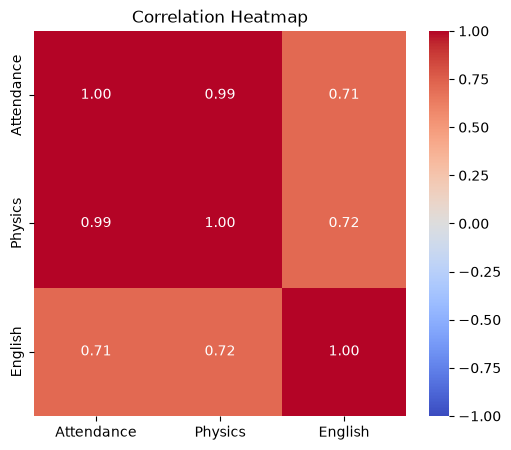

In [11]:
df = pd.DataFrame({
    'Attendance': attendance,
    'Physics': physics,
    'English': english
})

plt.figure(figsize=(6,5))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

## Question 7: Solve a Business Equation System

In [12]:
A = np.array([
    [1, 1],
    [50, 80]
])

b = np.array([80, 5600])

x, y = linalg.solve(A, b)

print(f"Product A units: {x}")
print(f"Product B units: {y}")

print("\nEquation 1 verified:", x + y == 80)
print("Equation 2 verified:", 50 * x + 80 * y == 5600)

Product A units: 26.666666666666675
Product B units: 53.33333333333333

Equation 1 verified: True
Equation 2 verified: True


## Question 8: Business Revenue and Profit Visualization

In [13]:
months = np.array(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun'])
revenue = np.array([52000, 58000, 61000, 68000, 72000, 79000])
expenses = np.array([42000, 45000, 47000, 50000, 54000, 57000])

profit = revenue - expenses

x, = months.shape

print("Monthly Profit")
for i in range(x):
    print(f"{months[i]}: {profit[i]}")

Monthly Profit
Jan: 10000
Feb: 13000
Mar: 14000
Apr: 18000
May: 18000
Jun: 22000


Fig saved succesfully


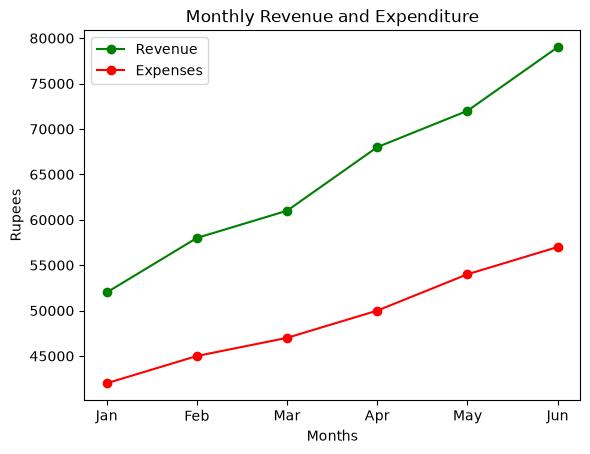

In [14]:
# 1. A line plot showing monthly revenue and expenses

plt.plot(months, revenue, color='green', marker='o', label='Revenue')
plt.plot(months, expenses, color='red', marker='o', label='Expenses')
plt.xlabel('Months')
plt.ylabel('Rupees')
plt.title('Monthly Revenue and Expenditure')
plt.legend()
plt.savefig("revenue_expenditure.png", dpi=150, bbox_inches='tight')
print('Fig saved succesfully')
plt.show()

Fig saved successfully


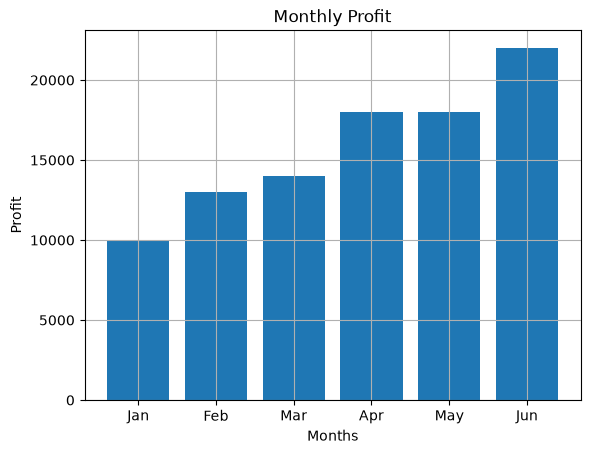

In [15]:
# 2. A bar chart showing monthly profit.

plt.bar(months, profit)
plt.title('Monthly Profit')
plt.xlabel('Months')
plt.ylabel('Profit')
plt.grid(True)
plt.savefig('monthly_profit.png', dpi=150, bbox_inches='tight')
print('Fig saved successfully')
plt.show()

Fig saved successfully


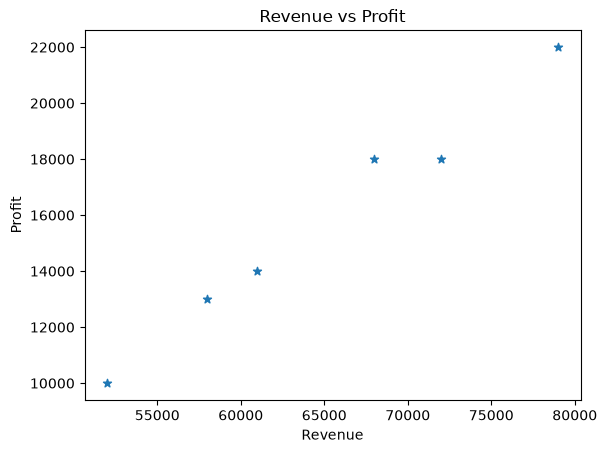

In [16]:
# 3. A scatter plot showing the relationship between revenue and profit.
plt.scatter(revenue, profit, marker='*')
plt.title('Revenue vs Profit')
plt.xlabel('Revenue')
plt.ylabel('Profit')
plt.savefig("revenue_profit.png", dpi=150, bbox_inches="tight")
print("Fig saved successfully")
plt.show()

Fig saved successfully


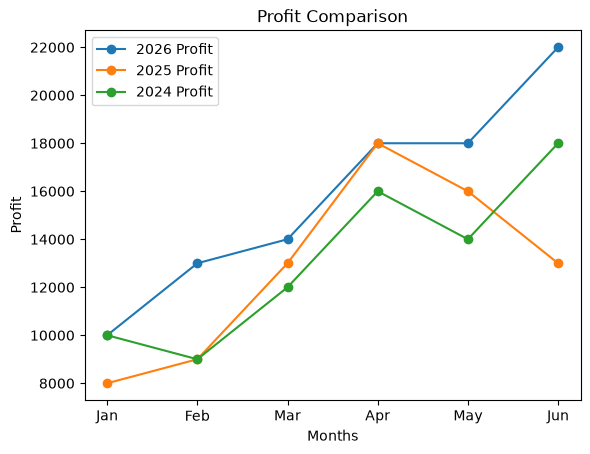

In [17]:
profit_2025 = np.array([8000, 9000, 13000, 18000, 16000, 13000])
profit_2024 = np.array([10000, 9000, 12000, 16000, 14000, 18000])

plt.plot(months, profit, label="2026 Profit", marker='o')
plt.plot(months, profit_2025, label="2025 Profit", marker='o')
plt.plot(months, profit_2024, label="2024 Profit", marker='o')
plt.xlabel('Months')
plt.ylabel('Profit')
plt.title('Profit Comparison')
plt.legend()
plt.savefig('profit_comparison.png', dpi=150, bbox_inches='tight')
print('Fig saved successfully')
plt.show()

# ASSIGNMENT 5 - Graph Traversal

## Question 1: Graph Representation and Breadth-First Search

In [18]:
from collections import deque

def build_graph(edges):
    graph = {}
    
    for edge in edges:
        u, v = edge.split("-")
        
        if u not in graph:
            graph[u] = []
        graph[u].append(v)
        
        if v not in graph:
            graph[v] = []
        graph[v].append(u)
    
    return graph

def bfs(graph, start):
    visited = set()
    queue = deque([start])
    visited.add(start)
    traversal_order = []

    while queue:
        current = queue.popleft()
        traversal_order.append(current)

        for neighbor in graph.get(current, []):
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(neighbor)

    return traversal_order

def main():
    edges = ["A-B", "A-C", "B-D", "C-E", "D-F"]
    graph = build_graph(edges)
    start_node = "A"
    print("Graph:", graph)
    print("BFS Traversal Order:", "-> ".join(bfs(graph, start_node)))

if __name__ == "__main__":
    main()

Graph: {'A': ['B', 'C'], 'B': ['A', 'D'], 'C': ['A', 'E'], 'D': ['B', 'F'], 'E': ['C'], 'F': ['D']}
BFS Traversal Order: A-> B-> C-> D-> E-> F


## Question 2: Depth-First Search Using Stack

In [19]:
def build_directed_graph(edges):
    graph = {}

    for edge in edges:
        u, v = edge.split("->")

        if u not in graph:
            graph[u] = []
        graph[u].append(v)

        if v not in graph:
            graph[v] = []

    return graph

def dfs_iterative(graph, start):
    visited = set()
    stack = [start]
    traversal_order = []

    while stack:
        current = stack.pop()

        if current not in visited:
            visited.add(current)
            traversal_order.append(current)

            for neighbor in reversed(graph.get(current, [])):
                if neighbor not in visited:
                    stack.append(neighbor)

    return traversal_order

def main():
    edges = ['A->B', 'A->C', 'B->D', 'C->E', 'D->F', 'E->F']
    graph = build_directed_graph(edges)
    print("Graph:", graph)
    start_node = "A"
    result = dfs_iterative(graph, start_node)
    print("-> ".join(result))

if __name__ == "__main__":
    main()

Graph: {'A': ['B', 'C'], 'B': ['D'], 'C': ['E'], 'D': ['F'], 'E': ['F'], 'F': []}
A-> B-> D-> F-> C-> E


## Question 3: Find Nodes at a Given Distance

In [20]:
from collections import deque

def find_nodes_at_distance_k(graph, start, k):
    if k < 0:
        return []
    if k == 0:
        return [start] if start in graph else []

    visited = set()
    queue = deque([(start, 0)])
    visited.add(start)
    result = []

    while queue:
        current, distance = queue.popleft()

        if distance == k:
            result.append(current)
            continue

        if distance > k:
            continue

        for neighbor in graph.get(current, []):
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append((neighbor, distance + 1))

    return result

def main():
    edges = ['A-B', 'A-C', 'B-D', 'B-E', 'C-F']
    graph = build_graph(edges)
    print("Graph:", graph)
    start_node = 'A'
    k = 2
    result = find_nodes_at_distance_k(graph, start_node, k)
    if result:
        print(f"Nodes at distance {k}:", " ".join(result))
    else:
        print(f"No nodes found at distance {k}.")

if __name__ == "__main__":
    main()

Graph: {'A': ['B', 'C'], 'B': ['A', 'D', 'E'], 'C': ['A', 'F'], 'D': ['B'], 'E': ['B'], 'F': ['C']}
Nodes at distance 2: D E F


## Question 4: Find the Shortest Route

In [21]:
from collections import deque

def find_shortest_path(graph, source, destination):
    if source == destination:
        return [source], 0
    if source not in graph:
        return None, None

    visited = set()
    queue = deque([(source, [source])])
    visited.add(source)

    while queue:
        current, path = queue.popleft()
        if current == destination:
            return path, len(path) - 1

        for neighbor in graph.get(current, []):
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append((neighbor, path + [neighbor]))

    return None, None

def main():
    edges = ['A-B', 'A-C', 'B-D', 'C-D']
    graph = build_graph(edges)
    print("Graph:", graph)
    source = 'A'
    destination = 'D'
    shortest_path, num_edges = find_shortest_path(graph, source, destination)
    if shortest_path:
        print(f"Shortest path from {source} to {destination}:", "-> ".join(shortest_path), f".Edges: {num_edges}")
    else:
        print(f"No path found from {source} to {destination}")

if __name__ == "__main__":
    main()

Graph: {'A': ['B', 'C'], 'B': ['A', 'D'], 'C': ['A', 'D'], 'D': ['B', 'C']}
Shortest path from A to D: A-> B-> D .Edges: 2


## Question 5: Find Connected Components

In [22]:
from collections import deque

def bfs_component(graph, start, visited):
    visited.add(start)
    queue = deque([start])
    component = []

    while queue:
        current = queue.popleft()
        component.append(current)

        for neighbor in graph.get(current, []):
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(neighbor)

    return component

def find_connected_components(graph):
    visited = set()
    components = []

    for node in graph:
        if node not in visited:
            component = bfs_component(graph, node, visited)
            components.append(component)

    return components

def main():
    edges = ['A-B', 'B-C', 'E-F', 'H-I']
    graph = build_graph(edges)
    components = find_connected_components(graph)
    print(f"Number of connected nodes: {len(components)}")
    for i, component in enumerate(components, 1):
        print(f"Component {i}: ", " ".join(component))

if __name__ == "__main__":
    main()

Number of connected nodes: 3
Component 1:  A B C
Component 2:  E F
Component 3:  H I


## Question 6: Detect a Cycle in a Data Pipeline

In [23]:
def has_cycle_util(node, graph, visited, recursion_stack):
    visited.add(node)
    recursion_stack.add(node)

    for neighbor in graph.get(node, []):
        if neighbor not in visited:
            if has_cycle_util(neighbor, graph, visited, recursion_stack):
                return True
            elif neighbor in recursion_stack:
                return True

    recursion_stack.remove(node)
    return False

def detect_cycle(graph):
    visited = set()
    recursion_stack = set()

    for node in graph:
        if node not in visited:
            if has_cycle_util(node, graph, visited, recursion_stack):
                return True

    return False

def main():
    edges_1 = ['Extract->Clean', 'Clean->Transform', 'Transform->Load']
    graph_1 = build_directed_graph(edges_1)
    edges_2 = ['Extract->Clean', 'Clean->Transform', 'Transform->Load', 'Transform->Clean']
    graph_2 = build_directed_graph(edges_2)
    
    if detect_cycle(graph_1):
        print("Example 1")
        print(graph_1)
        print("Pipeline contains a cycle.")
    else:
        print("Example 1")
        print(graph_1)
        print("Pipeline is cycle-free.")

    print("-" * 90)

    if detect_cycle(graph_2):
        print("Example 2")
        print(graph_2)
        print("Pipeline contains a cycle.")
    else:
        print("Example 2")
        print(graph_2)
        print("Pipeline is cycle-free")

if __name__ == "__main__":
    main()

Example 1
{'Extract': ['Clean'], 'Clean': ['Transform'], 'Transform': ['Load'], 'Load': []}
Pipeline is cycle-free.
------------------------------------------------------------------------------------------
Example 2
{'Extract': ['Clean'], 'Clean': ['Transform'], 'Transform': ['Load', 'Clean'], 'Load': []}
Pipeline is cycle-free


## Question 7: Data Pipeline Impact Analysis

In [25]:
from collections import deque

def build_directed_graph(edges):
    """
    Build an adjacency list representation of the directed graph from edge pairs.
    
    Args:
        edges: List of strings in format "A->B" representing directed connections
    
    Returns:
        Dictionary where keys are nodes and values are lists of adjacent nodes
    """
    graph = {}
    
    for edge in edges:
        # Split the edge string into source and destination nodes
        u, v = edge.split('->')
        
        # Add edge u -> v (directed)
        if u not in graph:
            graph[u] = []
        graph[u].append(v)
        
        # Ensure destination node exists in graph (even if it has no outgoing edges)
        if v not in graph:
            graph[v] = []
    
    return graph

def find_downstream_tasks_bfs(graph, failed_task):
    """
    Find all downstream tasks affected by a failed task using BFS.
    
    Args:
        graph: Adjacency list representation of the directed graph
        failed_task: The task that failed
    
    Returns:
        List of downstream tasks affected by the failure
    """
    # Check if the task exists in the graph
    if failed_task not in graph:
        return None  # Task not found
    
    # Initialize visited set to track explored nodes
    visited = set()
    
    # Initialize queue with the failed task
    queue = deque([failed_task])
    
    # Mark failed task as visited
    visited.add(failed_task)
    
    # List to store downstream tasks
    downstream_tasks = []
    
    # Continue until queue is empty
    while queue:
        # Dequeue a task from the front of the queue
        current = queue.popleft()
        
        # Explore all dependencies of the current task (tasks that depend on it)
        for neighbor in graph.get(current, []):
            # If neighbor hasn't been visited yet
            if neighbor not in visited:
                # Mark it as visited
                visited.add(neighbor)
                # Add to downstream tasks
                downstream_tasks.append(neighbor)
                # Enqueue it for further exploration
                queue.append(neighbor)
    
    return downstream_tasks

def main():
    """
    Main function to find downstream tasks affected by a failed task.
    """
    # Input dependencies as specified in the problem
    edges = [
        "raw_customer->clean_customer",
        "raw_order->clean_order",
        "clean_customer->customer_transform",
        "clean_order->order_transform",
        "customer_transform->warehouse",
        "order_transform->warehouse",
        "warehouse->dashboard"
    ]
    
    # Build the directed graph
    graph = build_directed_graph(edges)
    
    # Get the failed task from user input
    failed_task = input("Enter the failed task: ").strip()
    
    # Find downstream tasks
    result = find_downstream_tasks_bfs(graph, failed_task)
    
    # Display results
    if result is None:
        print("Task not found")
    elif not result:
        print("No downstream tasks")
    else:
        print("Affected tasks:")
        for task in result:
            print(task)

if __name__ == "__main__":
    main()

Enter the failed task:  warehouse


Affected tasks:
dashboard


## Question 8: Course Scheduling (Topological Sort)

In [26]:
def build_graph_from_prerequisites(prerequisites):
    graph = {}

    for course, prereq in prerequisites:
        if prereq not in graph:
            graph[prereq] = []
        graph[prereq].append(course)

        if course not in graph:
            graph[course] = []

    return graph

def dfs_topological_sort_util(node, graph, visited, recursion_stack, result):
    visited.add(node)
    recursion_stack.add(node)

    for neighbor in graph.get(node, []):
        if neighbor not in visited:
            if dfs_topological_sort_util(neighbor, graph, visited, recursion_stack, result):
                return True
            elif neighbor in recursion_stack:
                return True

    recursion_stack.remove(node)
    result.append(node)
    return False

def find_course_order(n, prerequisites):
    graph = build_graph_from_prerequisites(prerequisites)
    visited = set()
    recursion_stack = set()
    result = []
    all_nodes = set(graph.keys())

    for node in all_nodes:
        if node not in visited:
            if dfs_topological_sort_util(node, graph, visited, recursion_stack, result):
                return []

    result.reverse()
    return result

def main():
    n = 4
    prerequisites = [[3004, 1023], [3004, 2005], [5006, 3004], [5032, 3004]]
    order = find_course_order(n, prerequisites)

    if order:
        print("Valid Course Order:")
        print(order)
    else:
        print("[]")

if __name__ == "__main__":
    main()

Valid Course Order:
[1023, 2005, 3004, 5006, 5032]


# Assignment 4: Searching & Sorting

## Q1. Pair Sum to Target

In [27]:
arr = [3, 5, 6, 7, 8, 10, 12]
T = 15

i = 0
j = len(arr) - 1

print("Output:")

while i < j:
    if (arr[i] + arr[j]) == T:
        print(f"{arr[i]} and {arr[j]}")
        i += 1
        j -= 1
    elif (arr[i] + arr[j]) < T:
        i += 1
    else:
        j -= 1

Output:
3 and 12
5 and 10
7 and 8


## Q2. Sort an Array of 0’s, 1’s and 2’s

In [28]:
# Question 2: Sort an Array of 0s, 1s and 2s

arr = [0, 0, 1, 1, 2, 2, 0, 1, 0, 1, 2, 1, 0, 2]

low = 0
mid = 0
high = len(arr) - 1

while mid <= high:

    if arr[mid] == 0:
        # Move 0 to the beginning
        arr[low], arr[mid] = arr[mid], arr[low]
        low += 1
        mid += 1

    elif arr[mid] == 1:
        # 1 is already in the correct middle section
        mid += 1

    else:
        # Move 2 to the end
        arr[mid], arr[high] = arr[high], arr[mid]
        high -= 1

print(arr)

[0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2]


# ASSIGNMENT 3

## Question 1: Find the Closest Value

In [29]:
def closest_value(numbers, target):
    close = max(numbers)
    index = 0
    for i in range(len(numbers)):
        if close > (abs(numbers[i] - target)):
            close = numbers[i]
            index = i
    return close, index

numbers = [48, 12, 56, 25, 37]
target = 40

closest_value, index = closest_value(numbers, target)
print("Closest Value:", closest_value)
print("Index:", index)

Closest Value: 37
Index: 4


## Question 2: First and Last Occurrence Using Binary Search

In [30]:
# Binary Search Algorithm

def binary_search(arr, target):
    low = 0
    high = len(arr) - 1

    while low <= high:
        mid = low + (high - low) // 2

        if arr[mid] == target:
            return mid

        elif arr[mid] < target:
            low = mid + 1

        else:
            high = mid - 1

    return -1

In [31]:
def first_occurrence(arr, target):
    low = 0
    high = len(arr) - 1
    first = -1

    while low <= high:
        mid = low + (high - low) // 2

        if arr[mid] == target:
            first = mid
            high = mid - 1
        elif arr[mid] < target:
            low = mid + 1
        else:
            high = mid - 1

    return first

def last_occurrence(arr, target):
    low = 0
    high = len(arr) - 1
    last = -1

    while low <= high:
        mid = low + (high - low) // 2

        if arr[mid] == target:
            last = mid
            low = mid + 1
        elif arr[mid] < target:
            low = mid + 1
        else:
            high = mid - 1

    return last

numbers = [2, 4, 4, 4, 7, 9, 9, 12]
target = 4

first = first_occurrence(numbers, target)
last = last_occurrence(numbers, target)

print("First occurrence:", first)
print("Last occurrence:", last)

First occurrence: 1
Last occurrence: 3


## Question 3: Search in a Rotated Sorted Array

In [32]:
def search_rotated(arr, target):
    low = 0
    high = len(arr) - 1

    while low <= high:
        mid = low + (high - low) // 2

        if arr[mid] == target:
            return mid

        if arr[low] <= arr[mid]:

            if arr[low] <= k < arr[mid]:
                high = mid - 1
            else:
                low = mid + 1

        else:

            if arr[mid] < k <= arr[high]:
                low = mid + 1
            else:
                high = mid - 1

    return -1

nums = [4, 5, 6, 7, 0, 1, 2]
k = 0

result = search_rotated(nums, k)

print(result)

4


## Question 4: Sort According to Distance from a Given Value

In [33]:
def insertion_sort(arr):

    for i in range(1, len(arr)):
        key = arr[i]
        j = i - 1

        while j >= 0 and arr[j] > key:
            arr[j + 1] = arr[j]
            j -= 1
            
        arr[j + 1] = key

    return arr

In [34]:
# Question 4: Sort According to Distance from a Given Value

numbers = [10, 5, 3, 9, 2]
x = 7

# Insertion Sort based on distance from x
for i in range(1, len(numbers)):
    current = numbers[i]
    current_distance = abs(current - x)

    j = i - 1

    # Move elements with a greater distance to the right
    while j >= 0 and abs(numbers[j] - x) > current_distance:
        numbers[j + 1] = numbers[j]
        j -= 1

    numbers[j + 1] = current

print(numbers)

[5, 9, 10, 3, 2]


## Question 5: Special Even-Odd Sorting

In [35]:
# Question 5: Special Even-Odd Sorting

numbers = [7, 2, 9, 4, 1, 8, 3, 6]

# Separate even and odd numbers
even = []
odd = []

for number in numbers:
    if number % 2 == 0:
        even.append(number)
    else:
        odd.append(number)


# Sort even numbers in ascending order using Bubble Sort
for i in range(len(even)):
    for j in range(0, len(even) - i - 1):
        if even[j] > even[j + 1]:
            even[j], even[j + 1] = even[j + 1], even[j]


# Sort odd numbers in descending order using Bubble Sort
for i in range(len(odd)):
    for j in range(0, len(odd) - i - 1):
        if odd[j] < odd[j + 1]:
            odd[j], odd[j + 1] = odd[j + 1], odd[j]


# Combine the two lists
result = even + odd

print(result)

[2, 4, 6, 8, 9, 7, 3, 1]


## Question 6: Merge Two Sorted Lists

In [36]:
# Question 6: Merge Two Sorted Lists

list1 = [2, 6, 9, 15, 21]
list2 = [1, 4, 10, 18, 25]

merged = []

i = 0
j = 0

# Compare elements from both lists
while i < len(list1) and j < len(list2):

    if list1[i] <= list2[j]:
        merged.append(list1[i])
        i += 1
    else:
        merged.append(list2[j])
        j += 1


# Add remaining elements from list1
while i < len(list1):
    merged.append(list1[i])
    i += 1


# Add remaining elements from list2
while j < len(list2):
    merged.append(list2[j])
    j += 1


print(merged)

[1, 2, 4, 6, 9, 10, 15, 18, 21, 25]


## Question 7: Partition a List Around a Pivot

In [37]:
# Question 7: Partition a List Around a Pivot

numbers = [9, 4, 7, 3, 10, 5]
pivot = 5

smaller = []
greater = []

for number in numbers:

    if number < pivot:
        smaller.append(number)

    elif number > pivot:
        greater.append(number)

    # If number == pivot, we don't add it here


# Put the pivot exactly once between the two groups
result = smaller + [pivot] + greater

print(result)

[4, 3, 5, 9, 7, 10]


## Question 8: Count the Number of Incorrect Positions

In [38]:
# Question 8: Count the Number of Incorrect Positions

numbers = [1, 3, 2, 4, 5]

# Make a copy of the list
sorted_numbers = numbers.copy()

# Sort the copy using Bubble Sort
for i in range(len(sorted_numbers)):
    for j in range(0, len(sorted_numbers) - i - 1):
        if sorted_numbers[j] > sorted_numbers[j + 1]:
            sorted_numbers[j], sorted_numbers[j + 1] = (
                sorted_numbers[j + 1],
                sorted_numbers[j]
            )

# Count positions that are different
different_positions = 0

for i in range(len(numbers)):
    if numbers[i] != sorted_numbers[i]:
        different_positions += 1

print("Number of different positions:", different_positions)

Number of different positions: 2


# ASSIGNMENT 2: Data Manipulation Using Python and Pandas

In [23]:
# Imports
import pandas as pd

## Q1. Reading the Dataset

In [48]:
df = pd.read_csv("students.csv")
df.head()

,Roll_No,Name,Dept,Maths,Physics,Programming,Attendance
0,101,Ram,CSE,78,82,91,88
1,102,John,ECE,65,70,58,92
2,103,Athul,CSE,90,85,95,76
3,104,Shruthi,ME,55,60,45,68
4,105,Anjali,CSE,88,79,84,95


In [49]:
df.tail()

,Roll_No,Name,Dept,Maths,Physics,Programming,Attendance
5,106,Monica,ECE,72,68,77,81
6,107,Luke,ME,40,52,38,60
7,108,Steve,CSE,95,91,89,90
8,109,Meera,ECE,60,74,66,73
9,110,Arjun,ME,82,77,80,85


## Q2. Exploring the Dataset

In [50]:
df.shape

(10, 7)

In [51]:
df.columns

Index(['Roll_No', 'Name', 'Dept', 'Maths', 'Physics', 'Programming',
       'Attendance'],
      dtype='str')

In [53]:
df.dtypes

Roll_No        int64
Name             str
Dept             str
Maths          int64
Physics        int64
Programming    int64
Attendance     int64
dtype: object

## Q3. Selecting and Filtering Data

In [61]:
df[["Name", "Programming"]]

,Name,Programming
0,Ram,91
1,John,58
2,Athul,95
3,Shruthi,45
4,Anjali,84
5,Monica,77
6,Luke,38
7,Steve,89
8,Meera,66
9,Arjun,80


In [63]:
df[df["Dept"] == "CSE"]

,Roll_No,Name,Dept,Maths,Physics,Programming,Attendance
0,101,Ram,CSE,78,82,91,88
2,103,Athul,CSE,90,85,95,76
4,105,Anjali,CSE,88,79,84,95
7,108,Steve,CSE,95,91,89,90


In [64]:
df[df["Attendance"] >= 75]

,Roll_No,Name,Dept,Maths,Physics,Programming,Attendance
0,101,Ram,CSE,78,82,91,88
1,102,John,ECE,65,70,58,92
2,103,Athul,CSE,90,85,95,76
4,105,Anjali,CSE,88,79,84,95
5,106,Monica,ECE,72,68,77,81
7,108,Steve,CSE,95,91,89,90
9,110,Arjun,ME,82,77,80,85


## Q4. Writing Functions

In [67]:
def total_marks(maths, physics, programming):
    return maths + physics + programming

df["Total"] = df.apply(lambda x: total_marks(x["Maths"], x["Physics"], x["Programming"]), axis=1)

df

,Roll_No,Name,Dept,Maths,Physics,Programming,Attendance,Total
0,101,Ram,CSE,78,82,91,88,251
1,102,John,ECE,65,70,58,92,193
2,103,Athul,CSE,90,85,95,76,270
3,104,Shruthi,ME,55,60,45,68,160
4,105,Anjali,CSE,88,79,84,95,251
5,106,Monica,ECE,72,68,77,81,217
6,107,Luke,ME,40,52,38,60,130
7,108,Steve,CSE,95,91,89,90,275
8,109,Meera,ECE,60,74,66,73,200
9,110,Arjun,ME,82,77,80,85,239


## Q5. Average Marks

In [68]:
def average_marks(total):
    return total / 3

df["Average"] = df.apply(lambda x: average_marks(x["Total"]), axis=1)

df

,Roll_No,Name,Dept,Maths,Physics,Programming,Attendance,Total,Average
0,101,Ram,CSE,78,82,91,88,251,83.666667
1,102,John,ECE,65,70,58,92,193,64.333333
2,103,Athul,CSE,90,85,95,76,270,90.000000
3,104,Shruthi,ME,55,60,45,68,160,53.333333
4,105,Anjali,CSE,88,79,84,95,251,83.666667
5,106,Monica,ECE,72,68,77,81,217,72.333333
6,107,Luke,ME,40,52,38,60,130,43.333333
7,108,Steve,CSE,95,91,89,90,275,91.666667
8,109,Meera,ECE,60,74,66,73,200,66.666667
9,110,Arjun,ME,82,77,80,85,239,79.666667


## Q6. Using Lambda Functions

In [69]:
df["Result"] = df["Average"].apply(lambda x: "Pass" if x >= 50 else "Fail")
df

,Roll_No,Name,Dept,Maths,Physics,Programming,Attendance,Total,Average,Result
0,101,Ram,CSE,78,82,91,88,251,83.666667,Pass
1,102,John,ECE,65,70,58,92,193,64.333333,Pass
2,103,Athul,CSE,90,85,95,76,270,90.000000,Pass
3,104,Shruthi,ME,55,60,45,68,160,53.333333,Pass
4,105,Anjali,CSE,88,79,84,95,251,83.666667,Pass
5,106,Monica,ECE,72,68,77,81,217,72.333333,Pass
6,107,Luke,ME,40,52,38,60,130,43.333333,Fail
7,108,Steve,CSE,95,91,89,90,275,91.666667,Pass
8,109,Meera,ECE,60,74,66,73,200,66.666667,Pass
9,110,Arjun,ME,82,77,80,85,239,79.666667,Pass


## Q7. Grade Calculation

In [70]:
df["Grade"] = df["Average"].apply(lambda x:
                                  "A" if 100 >= x >= 90 else
                                  "B" if 89 >= x >= 80 else
                                  "C" if 79 >= x >= 70 else
                                  "D" if 69 >= x >= 60 else
                                  "F"
                                 )
df

,Roll_No,Name,Dept,Maths,Physics,Programming,Attendance,Total,Average,Result,Grade
0,101,Ram,CSE,78,82,91,88,251,83.666667,Pass,B
1,102,John,ECE,65,70,58,92,193,64.333333,Pass,D
2,103,Athul,CSE,90,85,95,76,270,90.000000,Pass,A
3,104,Shruthi,ME,55,60,45,68,160,53.333333,Pass,F
4,105,Anjali,CSE,88,79,84,95,251,83.666667,Pass,B
5,106,Monica,ECE,72,68,77,81,217,72.333333,Pass,C
6,107,Luke,ME,40,52,38,60,130,43.333333,Fail,F
7,108,Steve,CSE,95,91,89,90,275,91.666667,Pass,A
8,109,Meera,ECE,60,74,66,73,200,66.666667,Pass,D
9,110,Arjun,ME,82,77,80,85,239,79.666667,Pass,F


## Q8. Dictionary

In [71]:
student_dict = dict(zip(df["Roll_No"], df["Name"]))

student_dict

{101: 'Ram',
 102: 'John',
 103: 'Athul',
 104: 'Shruthi',
 105: 'Anjali',
 106: 'Monica',
 107: 'Luke',
 108: 'Steve',
 109: 'Meera',
 110: 'Arjun'}

## Q9. Department Performance Analysis

In [74]:
def department_report(df, dept):
    dept_df = df[df["Dept"] == dept]

    return {
        "Total number of students" : len(dept_df),
        "Average Programming marks" : dept_df["Programming"].mean(),
        "Highest Programming marks" : dept_df["Programming"].max()
    }

department_report(df, "CSE")

{'Total number of students': 4,
 'Average Programming marks': np.float64(89.75),
 'Highest Programming marks': np.int64(95)}

## Q10. Students Requiring Extra Support

In [77]:
support_df = df[(df["Average"] < 60) | (df["Attendance"] < 75)]

support_df

,Roll_No,Name,Dept,Maths,Physics,Programming,Attendance,Total,Average,Result,Grade
3,104,Shruthi,ME,55,60,45,68,160,53.333333,Pass,F
6,107,Luke,ME,40,52,38,60,130,43.333333,Fail,F
8,109,Meera,ECE,60,74,66,73,200,66.666667,Pass,D


## Question 13

In [79]:
class Student:
    def __init__(self, roll_no, name, dept):
        self.roll_no = roll_no
        self.name = name
        self.dept = dept
        self.maths = 0
        self.physics = 0
        self.programming = 0
        self.attendance = 0
    
    def set_maths(self, marks):
        self.maths = marks

    def set_physics(self, marks):
        self.physics = marks

    def set_programming(self, marks):
        self.programming = marks

    def set_attendance(self, attendance):
        self.attendance = attendance

    def average_marks(self):
        return (self.maths + self.physics + self.programming) / 3

    def scholarship_eligible(self):
        return self.average_marks() >= 85 and self.attendance >= 90

    def check_performance(self):
        if (self.maths < 30 and
            self.physics < 30 and
            self.programming < 30
           ):
            print("Warning! Marks less than 30% in all courses")
        else:
            print("Satisfactory")

    def __str__(self):
        return (
            f"Roll No: {self.roll_no}, "
            f"Name: {self.name}, "
            f"Dept: {self.dept}, "
            f"Average: {self.average_marks():.2f}"
        )

students = []

for _, row in df.iterrows():
    student = Student(row["Roll_No"], row["Name"], row["Dept"])
    student.set_maths(row["Maths"])
    student.set_physics(row["Physics"])
    student.set_programming(row["Programming"])
    student.set_attendance(row["Attendance"])

    students.append(student)

for student in students:
    print(student)
    print("Scholarship Eligible:", student.scholarship_eligible())
    print(student.check_performance())
    print("-" * 40)

Roll No: 101, Name: Ram, Dept: CSE, Average: 83.67
Scholarship Eligible: False
Satisfactory
None
----------------------------------------
Roll No: 102, Name: John, Dept: ECE, Average: 64.33
Scholarship Eligible: False
Satisfactory
None
----------------------------------------
Roll No: 103, Name: Athul, Dept: CSE, Average: 90.00
Scholarship Eligible: False
Satisfactory
None
----------------------------------------
Roll No: 104, Name: Shruthi, Dept: ME, Average: 53.33
Scholarship Eligible: False
Satisfactory
None
----------------------------------------
Roll No: 105, Name: Anjali, Dept: CSE, Average: 83.67
Scholarship Eligible: False
Satisfactory
None
----------------------------------------
Roll No: 106, Name: Monica, Dept: ECE, Average: 72.33
Scholarship Eligible: False
Satisfactory
None
----------------------------------------
Roll No: 107, Name: Luke, Dept: ME, Average: 43.33
Scholarship Eligible: False
Satisfactory
None
----------------------------------------
Roll No: 108, Name: St

## Q12. Student Performance Report

In [82]:
print("---------------------- Student Report ------------------------")
print()
print("Total Students:", len(df))
top_performer = df.loc[df["Total"].idxmax(), "Name"]
print("Top Performer:", top_performer)
print("Highest Total Marks:", df["Total"].max())
print("Students Passed:", len(df[df["Result"] == "Pass"]))
print("Students Failed:", len(df[df["Result"] == "Fail"]))
print("--------------------------------------------------------------")
print("CSE Students:", len(df[df["Dept"] == "CSE"]))
print("ME Students:", len(df[df["Dept"] == "ME"]))
print("ECE Students:", len(df[df["Dept"] == "ECE"]))
print("Average attendance:", df["Attendance"].mean())
print("--------------------------------------------------------------")

---------------------- Student Report ------------------------

Total Students: 10
Top Performer: Steve
Highest Total Marks: 275
Students Passed: 9
Students Failed: 1
--------------------------------------------------------------
CSE Students: 4
ME Students: 3
ECE Students: 3
Average attendance: 80.8
--------------------------------------------------------------


## Question 13 (Class-Based Programming)

In [83]:
# Implementation of a Stack using an Array
class Stack:
    def __init__(self):
        self.stack = []
    
    def push(self, item):
        self.stack.append(item)
        print(f"{item} pushed onto the stack")
    
    def pop(self):
        if len(self.stack) == 0:
            print("Stack Underflow")
        else:
            self.stack.pop()
            print("Item popped")
    
    def display(self):
        print(self.stack)

stack = Stack()
stack.display()
stack.push(13)
stack.display()
stack.push(13)
stack.display()
stack.push(78)
stack.display()
stack.push(67)
stack.display()
stack.pop()
stack.display()
stack.pop()
stack.display()

[]
13 pushed onto the stack
[13]
13 pushed onto the stack
[13, 13]
78 pushed onto the stack
[13, 13, 78]
67 pushed onto the stack
[13, 13, 78, 67]
Item popped
[13, 13, 78]
Item popped
[13, 13]


## Question 14 (Class-Based Programming)

In [6]:
class Node:
    def __init__(self, data):
        self.data = data
        self.next = None

class Stack:
    def __init__(self):
        self.top = None

    def push(self, data):
        new_node = Node(data)
        new_node.next = self.top
        self.top = new_node
        print(f"{self.top.data} pushed into the stack!")

    def pop(self):
        if self.top is None:
            print("Stack Underflow")
        else:
            popped = self.top.data
            self.top = self.top.next
            print(f"{popped} popped out of the stack.")

    def display(self):
        if self.top is None:
            print("Empty Stack")
        else:
            current = self.top
            print("Stack:", end=" ")

            while current:
                print(current.data, end=" ")
                current = current.next
            print()

stack = Stack()
stack.push(13)
stack.display()
stack.push(13)
stack.display()
stack.push(78)
stack.display()
stack.push(67)
stack.display()
stack.pop()
stack.display()
stack.pop()
stack.display()

13 pushed into the stack!
Stack: 13 
13 pushed into the stack!
Stack: 13 13 
78 pushed into the stack!
Stack: 78 13 13 
67 pushed into the stack!
Stack: 67 78 13 13 
67 popped out of the stack.
Stack: 78 13 13 
78 popped out of the stack.
Stack: 13 13 


# ASSIGNMENT 1

## 1. Temperature Conversion

In [4]:
def temp_conversion():
    celsius = float(input("Enter temperature in Celcius:"))
    fahrenheit = (9 / 5) * celsius + 32
    print("Temperature in Fahrenheit:", fahrenheit)

if __name__ == "__main__":
    temp_conversion()

Enter temperature in Celcius: 25


Temperature in Fahrenheit: 77.0


## 2. Simple Interest And Total Amount

In [5]:
def simple_interest():
    principal = float(input("Enter the Principal Amount:"))
    rate = float(input("Enter the Interest Rate:"))
    time = float(input("Enter Time in Years:"))

    interest = (principal * rate * time) / 100
    total = principal + interest

    print("Simple Interest:", interest)
    print("Total Amount:", total)

if __name__ == "__main__":
    simple_interest()

Enter the Principal Amount: 1000
Enter the Interest Rate: 18
Enter Time in Years: 2


Simple Interest: 360.0
Total Amount: 1360.0


## 3. Largest Number

In [6]:
def largest_number():
    num1 = int(input("Enter the first number:"))
    num2 = int(input("Enter the second number:"))
    num3 = int(input("Enter the third number:"))

    if num1 > num2 and num1 > num3:
        print("Largest number:", num1)
    elif num2 > num1 and num2 > num3:
        print("Largest number:", num2)
    elif num3 > num1 and num3 > num2:
        print("Largest number:", num3)
    else:
        print("Equal numbers exists!")

if __name__ == "__main__":
    largest_number()

Enter the first number: 14
Enter the second number: 27
Enter the third number: 19


Largest number: 27


## 4. Valid Triangle

In [14]:
def valid_triangle():
    side1 = float(input("Enter the first side:"))
    side2 = float(input("Enter the second side:"))
    side3 = float(input("Enter the third side:"))

    if (side2 + side3 > side1) and (side1 + side3 > side2) and (side1 + side2 > side3):
        print("The sides form a valid triangle")
    else:
        print("The sides do not form a valid triangle")

if __name__ == "__main__":
    valid_triangle()

Enter the first side: 2
Enter the second side: 3
Enter the third side: 4


The sides form a valid triangle


## 5. Reverse Digits

In [15]:
def reverse_digits():
    number = int(input("Enter a number:"))
    original = number
    reverse = 0

    while number > 0:
        digit = number % 10 # get the last digit
        reverse = reverse * 10 + digit
        number = number // 10 # removes the last digit

    print("Reversed number:", reverse)
    if original == reverse:
        print("The number is a palindrome")
    else:
        print("The number is not a palindrome")

if __name__ == "__main__":
    reverse_digits()

Enter a number: 1221


Reversed number: 1221
The number is a palindrome


## 6. Sum of Digits

In [16]:
def sum_of_digits():
    num = int(input("Enter a number:"))
    total = 0

    while num > 0:
        digit = num % 10
        total += digit
        num = num // 10

    print("Sum of digits:", total)

if __name__ == "__main__":
    sum_of_digits()

Enter a number: 5832


Sum of digits: 18


## 7. Displaying

In [17]:
def display_operations():
    name = input("Enter your name:")
    age = int(input("Enter your age:"))

    age += 1
    age_str = str(age)

    print("Hello " + name + ", you will be " + age_str + " years old next year.")

if __name__ == "__main__":
    display_operations()

Enter your name: Anesu
Enter your age: 25


Hello Anesu, you will be 26 years old next year.


## 8. GCD

In [21]:
def gcd():
    num1 = int(input("Enter the first number:"))
    num2 = int(input("Enter the second number:"))

    while num2 != 0:
        temp = num2
        num2 = num1 % num2
        num1 = temp

    print("GCD:", num1)

if __name__ == "__main__":
    gcd()

Enter the first number: 36
Enter the second number: 48


GCD: 12


## 9. Multiplication Table

In [23]:
def mul_table():
    num = int(input("Enter the number:"))
    limit = int(input("Enter the limit:"))

    for i in range(1, limit + 1):
        print(f"{num} x {i} = {7 * i}")

if __name__ == "__main__":
    mul_table()

Enter the number: 7
Enter the limit: 5


7 x 1 = 7
7 x 2 = 14
7 x 3 = 21
7 x 4 = 28
7 x 5 = 35


## 10. Pattern

In [31]:
def num_pattern():
    n = int(input("Enter a number:"))

    for i in range(1, n + 1):
        for j in range(1, i + 1):
            print(j, end=" ")
        print()

if __name__ == "__main__":
    num_pattern()

Enter a number: 5


1 
1 2 
1 2 3 
1 2 3 4 
1 2 3 4 5 


## 11. Star Pyramid

In [9]:
def star_pyramid():
    H = int(input("Enter height:"))

    for i in range(1, H + 1):
        for j in range(H - i):
            print(" ", end="")
        for k in range(2 * i - 1):
            print("*", end="")
        print()

if __name__ == "__main__":
    star_pyramid()

Enter height: 5


    *
   ***
  *****
 *******
*********


## 12. Integers

In [18]:
def calculate():
    n = int(input("Enter the number of elements:"))
    numbers = []
    total = 0
    largest = 0

    for i in range(n):
        num = int(input(f"Enter element {i + 1}:"))
        numbers.append(num)

    print("List elements:", numbers)

    for j in numbers:
        total += j
        if j > largest:
            largest = j

    print("Sum of elements:", total)
    print("Largest element:", largest)

if __name__ == "__main__":
    calculate()

Enter the number of elements: 5
Enter element 1: 12
Enter element 2: 7
Enter element 3: 25
Enter element 4: 10
Enter element 5: 16


List elements: [12, 7, 25, 10, 16]
Sum of elements: 70
Largest element: 25


## 13. Perfect Numbers

In [22]:
def is_perfect(n):
    total = 0
    for i in range(1, n):
        if n % i == 0:
            total += i
    return total == n

def main():
    limit = int(input("Enter the upper limit:"))
    print(f"Perfect numbers between 1 and {limit}:", end=" ")
    for i in range(1, limit + 1):
        if is_perfect(i):
            print(i, end=" ")

if __name__ == "__main__":
    main()

Enter the upper limit: 1000


Perfect numbers between 1 and 1000: 6 28 496 